# Spectral Index Baseline

Before judging what the U-Net contributes, it is worth asking how far a much simpler method gets. Solar modules are dark and absorb strongly in the near infrared, while the surrounding gravel desert is bright. A single spectral index with one threshold should therefore already separate most of the plants.

This notebook fits such a baseline on a 2020 scene and applies it, unchanged, to the 2026 scene. The same hand labels and the same metrics as in notebook 04 are used, so the two methods can be compared directly.

Unlike the U-Net, the index has no notion of context: it decides pixel by pixel and cannot tell bare ground inside a plant from the same ground outside it.

## Setup

In [8]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize

sys.path.append("../scripts")
from preprocessing import BASELINE_OFFSET

BASE_DIR = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
SCENE_DIR = RAW_DIR / "raster" / "sentinel2"
PREDICTIONS_DIR = BASE_DIR / "results" / "predictions"
EVALUATION_DIR = BASE_DIR / "results" / "evaluation"
FIGURES_DIR = BASE_DIR / "results" / "figures"

FIT_DAY = "2020-10-07"     # index and threshold are chosen on this scene
TEST_DAY = "2026-10-06"    # and then applied unchanged to this one

for folder in (PREDICTIONS_DIR, EVALUATION_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)


## Data

The scenes are read as reflectance, with the baseline offset of 1000 removed for scenes from 2022 onwards. No rescaling to 0-255 is needed here, because the index works on ratios rather than on absolute brightness.

In [9]:
def read_scene(day):
    """Return the four bands as reflectance, and the grid of the scene."""
    offset = BASELINE_OFFSET if int(day[:4]) >= 2022 else 0

    with rasterio.open(SCENE_DIR / f"talatan_{day}.tif") as src:
        bands = src.read().astype("float32") - offset
        grid = {"shape": src.shape, "transform": src.transform, "crs": src.crs,
                "pixel_area": abs(src.transform.a * src.transform.e)}

    blue, green, red, nir = np.clip(bands, 1, None)
    return {"blue": blue, "green": green, "red": red, "nir": nir}, grid


def label_mask(day, grid):
    """Rasterise the hand labels of one day on the grid of that scene."""
    polygons = gpd.read_file(RAW_DIR / "vectors" / f"own_labels_{day}.shp").to_crs(grid["crs"])
    polygons = polygons[polygons.geometry.notna() & ~polygons.geometry.is_empty]
    polygons["geometry"] = polygons.geometry.make_valid()
    polygons = polygons.explode(index_parts=False)
    polygons = polygons[(polygons.geom_type == "Polygon") & (polygons.area > 0)]
    return rasterize(polygons.geometry, out_shape=grid["shape"], transform=grid["transform"],
                     fill=0, default_value=1, dtype="uint8").astype(bool)


fit_bands, fit_grid = read_scene(FIT_DAY)
fit_truth = label_mask(FIT_DAY, fit_grid)

print(f"{FIT_DAY}: {fit_grid['shape'][0]} x {fit_grid['shape'][1]} pixels, "
      f"{fit_truth.sum() * fit_grid['pixel_area'] / 1e6:.1f} km² labelled")


2020-10-07: 4063 x 4860 pixels, 136.6 km² labelled


## Candidate Indices

Four candidates, each written so that high values mean PV. The first two use the contrast between the visible bands and the near infrared, which is where modules and sand differ most; the third is the inverted vegetation index; the fourth is simply darkness.

In [10]:
INDICES = {
    "blue_over_nir": lambda b: b["blue"] / b["nir"],
    "nd_blue_nir": lambda b: (b["blue"] - b["nir"]) / (b["blue"] + b["nir"]),
    "inverted_ndvi": lambda b: (b["red"] - b["nir"]) / (b["red"] + b["nir"]),
    "darkness": lambda b: -(b["blue"] + b["green"] + b["red"] + b["nir"]) / 4,
}

PERCENTILES = np.arange(50, 99.6, 0.5)


def scores(predicted, reference, pixel_area):
    true_positive = int((predicted & reference).sum())
    false_positive = int((predicted & ~reference).sum())
    false_negative = int((~predicted & reference).sum())
    return {
        "IoU": true_positive / max(true_positive + false_positive + false_negative, 1),
        "F1": 2 * true_positive / max(2 * true_positive + false_positive + false_negative, 1),
        "precision": true_positive / max(true_positive + false_positive, 1),
        "recall": true_positive / max(true_positive + false_negative, 1),
        "predicted_km2": predicted.sum() * pixel_area / 1e6,
    }


## Fitting

For every candidate, the threshold is varied over the percentiles of its own value range and the one with the highest IoU on the 2020 scene is kept. The index with the best score becomes the baseline.

In [11]:
rows = []
for name, index_function in INDICES.items():
    values = index_function(fit_bands)
    thresholds = np.percentile(values[::4, ::4], PERCENTILES)

    best = max(
        (scores(values > threshold, fit_truth, fit_grid["pixel_area"]) | {"threshold": float(threshold)}
         for threshold in thresholds),
        key=lambda row: row["IoU"],
    )
    rows.append({"index": name, **best})
    print(f"{name:16s} best IoU {best['IoU']:.3f} at threshold {best['threshold']:.4f}")

fit_results = pd.DataFrame(rows).set_index("index").round(3)
BEST_INDEX = fit_results["IoU"].idxmax()
BEST_THRESHOLD = fit_results.loc[BEST_INDEX, "threshold"]

print(f"\nSelected: {BEST_INDEX} > {BEST_THRESHOLD:.4f}")
fit_results


blue_over_nir    best IoU 0.219 at threshold 0.4986
nd_blue_nir      best IoU 0.219 at threshold -0.3346
inverted_ndvi    best IoU 0.070 at threshold -0.1884
darkness         best IoU 0.170 at threshold -1045.5000

Selected: blue_over_nir > 0.4990


,IoU,F1,precision,recall,predicted_km2,threshold
index,,,,,,
blue_over_nir,0.219,0.359,0.317,0.413,178.065,0.499
nd_blue_nir,0.219,0.359,0.317,0.413,178.065,-0.335
inverted_ndvi,0.070,0.130,0.074,0.536,986.992,-0.188
darkness,0.170,0.291,0.187,0.660,483.646,-1045.500


## Applying the Baseline to 2026

Index and threshold stay exactly as fitted on 2020. The resulting mask is written to `results/predictions/` so it can be opened next to the model output.

In [12]:
test_bands, test_grid = read_scene(TEST_DAY)
test_truth = label_mask(TEST_DAY, test_grid)

baseline_mask = INDICES[BEST_INDEX](test_bands) > BEST_THRESHOLD
baseline_path = PREDICTIONS_DIR / f"baseline_{TEST_DAY}.tif"

with rasterio.open(SCENE_DIR / f"talatan_{TEST_DAY}.tif") as src:
    profile = src.profile.copy()
profile.update(count=1, dtype="uint8", nodata=None)

with rasterio.open(baseline_path, "w", **profile) as dst:
    dst.write(baseline_mask.astype("uint8"), 1)

baseline_scores = scores(baseline_mask, test_truth, test_grid["pixel_area"])
print({key: round(value, 3) for key, value in baseline_scores.items()})


{'IoU': 0.356, 'F1': 0.525, 'precision': 0.542, 'recall': 0.509, 'predicted_km2': np.float64(320.264)}


## Comparison with the Model

The two methods side by side on the same scene and the same labels.

In [13]:
comparison = pd.DataFrame([{"method": f"index ({BEST_INDEX})", **baseline_scores}]).set_index("method")

model_metrics = EVALUATION_DIR / f"metrics_{TEST_DAY}.csv"
if model_metrics.exists():
    model_row = pd.read_csv(model_metrics, index_col=0).iloc[0]
    comparison.loc["U-Net"] = [model_row[column] for column in comparison.columns]

comparison["labelled_km2"] = test_truth.sum() * test_grid["pixel_area"] / 1e6
comparison = comparison.round(3)
comparison.to_csv(EVALUATION_DIR / f"baseline_comparison_{TEST_DAY}.csv")
comparison


,IoU,F1,precision,recall,predicted_km2,labelled_km2
method,,,,,,
index (blue_over_nir),0.356,0.525,0.542,0.509,320.264,340.908
U-Net,0.852,0.920,0.920,0.920,341.160,340.908


## Maps

Imagery, baseline and model on the 2026 scene. The index tends to follow the dark pixels themselves, while the model also closes the gaps between the module rows.

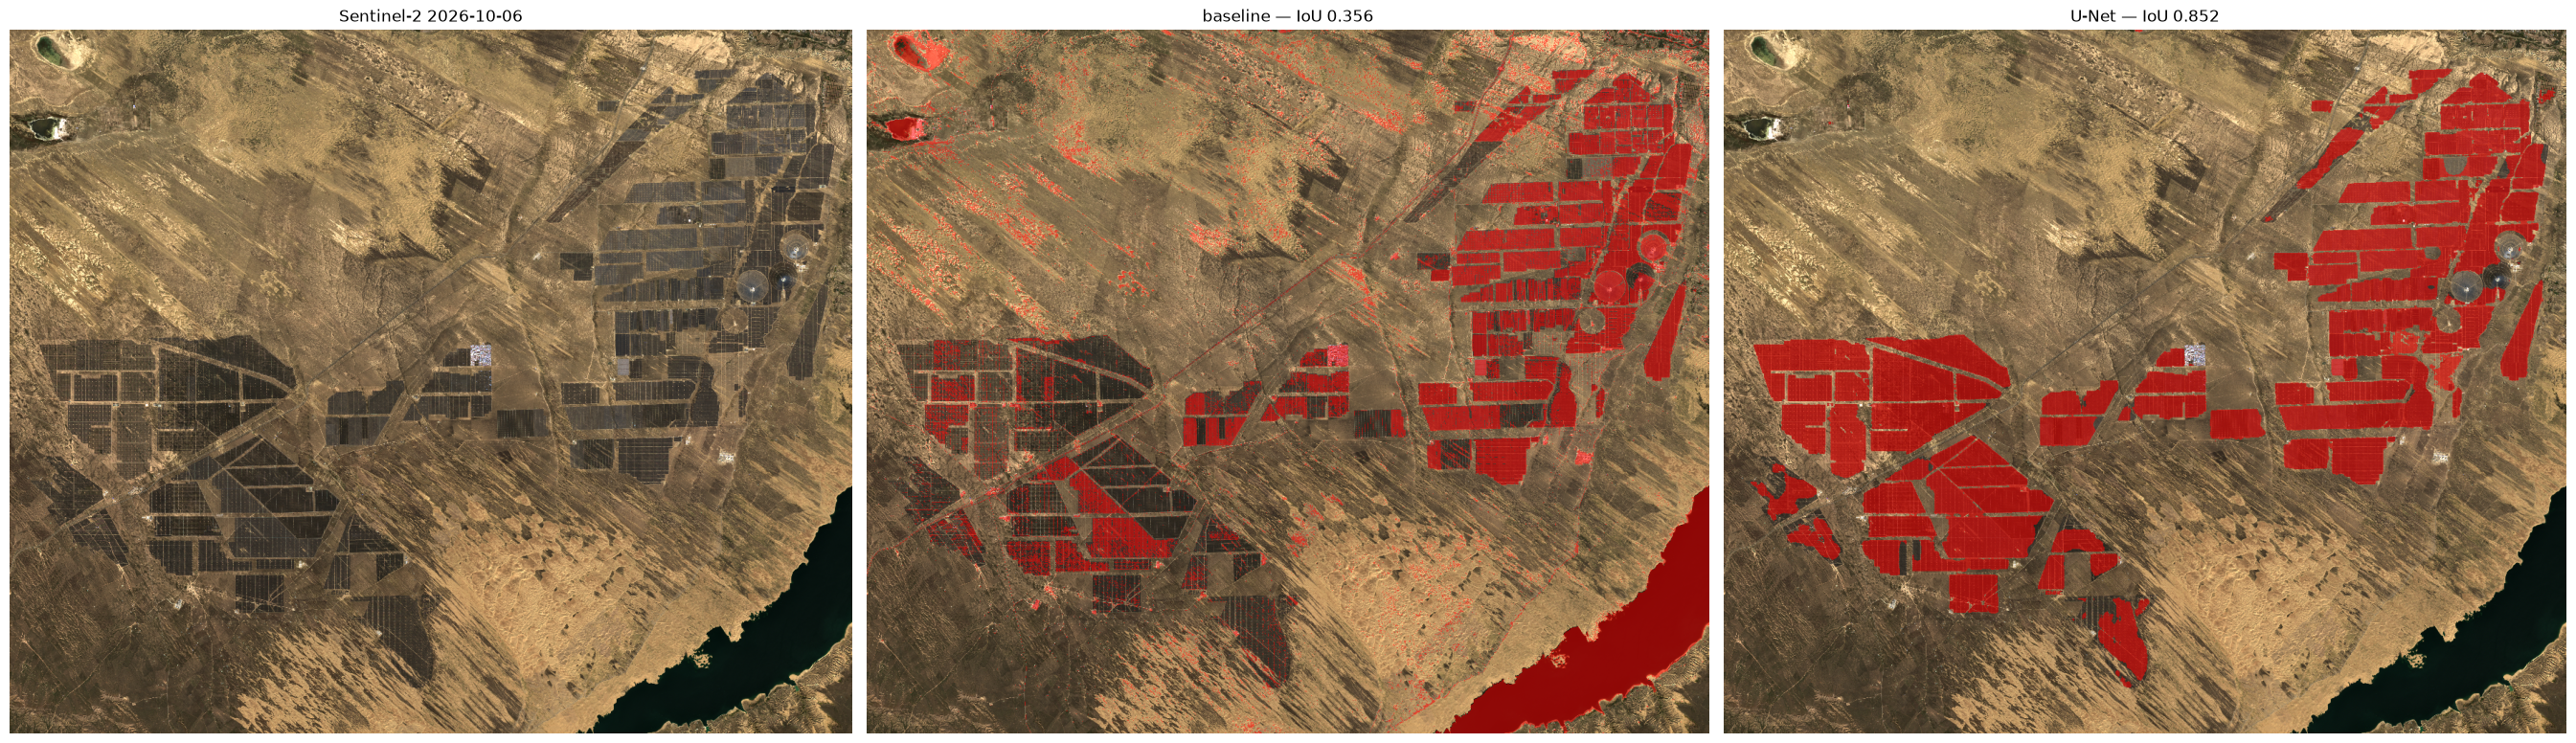

In [14]:
F = 4   # downsampling for display only
small_shape = (test_grid["shape"][0] // F, test_grid["shape"][1] // F)

with rasterio.open(SCENE_DIR / f"talatan_{TEST_DAY}.tif") as src:
    rgb = src.read([3, 2, 1], out_shape=(3, *small_shape)).astype("float32") - BASELINE_OFFSET
rgb = np.clip(np.moveaxis(rgb, 0, -1) / 3000, 0, 1)

panels = [("baseline", baseline_mask[::F, ::F][:small_shape[0], :small_shape[1]])]
model_path = PREDICTIONS_DIR / f"prediction_{TEST_DAY}.tif"
if model_path.exists():
    with rasterio.open(model_path) as src:
        panels.append(("U-Net", src.read(1, out_shape=small_shape) == 1))

fig, axes = plt.subplots(1, len(panels) + 1, figsize=(9 * (len(panels) + 1), 8))
axes[0].imshow(rgb)
axes[0].set_title(f"Sentinel-2 {TEST_DAY}")

for ax, (name, mask) in zip(axes[1:], panels):
    overlay = rgb.copy()
    overlay[mask] = 0.45 * overlay[mask] + 0.55 * np.array([1.0, 0.0, 0.0])
    ax.imshow(overlay)
    ax.set_title(f"{name} — IoU {comparison.loc[comparison.index[0] if name == 'baseline' else 'U-Net', 'IoU']:.3f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / f"baseline_comparison_{TEST_DAY}.png", dpi=150, bbox_inches="tight")
plt.show()
